# Stage 5: Temporal analysis

Annual research trends must use the original submission year, not the date of an updated arXiv version.

In [1]:
# Verifying the submission year variable is available in the final_document_clusters.csv

import pandas as pd
from pathlib import Path

base = next(
    p for p in [Path("artifacts"), Path("../artifacts")]
    if (p / "final_document_clusters.csv").exists()
)

docs = pd.read_csv(base / "final_document_clusters.csv")

temporal_cols = [
    c for c in docs.columns
    if any(s in c.lower() for s in ("year", "date", "submit"))
]

print("Temporal columns:", temporal_cols)
print("All columns:", docs.columns.tolist())

if temporal_cols:
    display(docs[temporal_cols].head(5))


Temporal columns: ['year']
All columns: ['id', 'year', 'clean_title', 'cluster_id']


,year
0,2021
1,2021
2,2021
3,2021
4,2021


## 1. Annual publication counts

In [2]:
# Annual publication distribution
annual_counts = (
    docs.groupby("year")
    .size()
    .reindex(range(2021, 2026), fill_value=0)
)

annual_summary = pd.DataFrame({
    "papers": annual_counts,
    "share_pct": (annual_counts / len(docs) * 100).round(2)
})

# Validate dataset coverage
assert annual_counts.sum() == 75110
assert annual_counts.min() > 0

print("Total papers:", annual_counts.sum())
display(annual_summary)


Total papers: 75110


,papers,share_pct
year,,
2021,8083,10.76
2022,8971,11.94
2023,13603,18.11
2024,20689,27.54
2025,23764,31.64


## 2. Identify growing and declining research topics

In [3]:
# Number of papers per cluster and year
counts = pd.crosstab(docs["cluster_id"], docs["year"])

# Share of each cluster within each year (%)
shares = counts.div(counts.sum(axis=0), axis=1) * 100

# Compare beginning and end of study period
trends = pd.DataFrame({
    "share_2021": shares[2021],
    "share_2025": shares[2025],
    "change_pp": shares[2025] - shares[2021]
})

# Add existing automatic topic descriptors
profiles = pd.read_csv(base / "final_cluster_profiles.csv")
trends = trends.join(
    profiles.set_index("cluster_id")["top_terms"]
)

print("Largest increases in relative share:")
display(trends.nlargest(8, "change_pp").round(2))

print("\nLargest decreases in relative share:")
display(trends.nsmallest(8, "change_pp").round(2))


Largest increases in relative share:


,share_2021,share_2025,change_pp,top_terms
cluster_id,,,,
149,0.02,2.66,2.63,"reasoning, models, reasoning models, thinking,..."
15,0.00,2.52,2.52,"rag, retrieval, retrieval augmented, augmented..."
19,0.25,2.35,2.10,"reward, rl, reinforcement, reinforcement learn..."
110,0.16,1.86,1.69,"agent, multi agent, multi, agents, llm, agent ..."
76,0.00,1.68,1.68,"llms, models, language, large language, langua..."
28,0.02,1.37,1.34,"safety, llms, harmful, alignment, safety align..."
25,0.01,1.34,1.33,"llm, llms, llm based, large language, large, b..."
71,0.27,1.51,1.24,"agents, agent, llm agents, llm, web, environme..."



Largest decreases in relative share:


,share_2021,share_2025,change_pp,top_terms
cluster_id,,,,
34,3.09,0.96,-2.14,"translation, machine translation, machine, mt,..."
63,2.13,0.40,-1.72,"word, words, sense, embeddings, word embedding..."
117,1.78,0.19,-1.59,"bert, model, models, bert model, bert based, b..."
60,2.05,0.53,-1.53,"question, qa, answering, question answering, a..."
38,1.78,0.37,-1.41,"summarization, summaries, abstractive, summary..."
62,1.71,0.35,-1.36,"relation, extraction, relation extraction, rel..."
151,1.42,0.17,-1.25,"pre, pre trained, trained, plms, trained langu..."
148,1.65,0.42,-1.23,"dialogue, dialogue systems, task oriented, ori..."


## 3. Visualise the development over five years

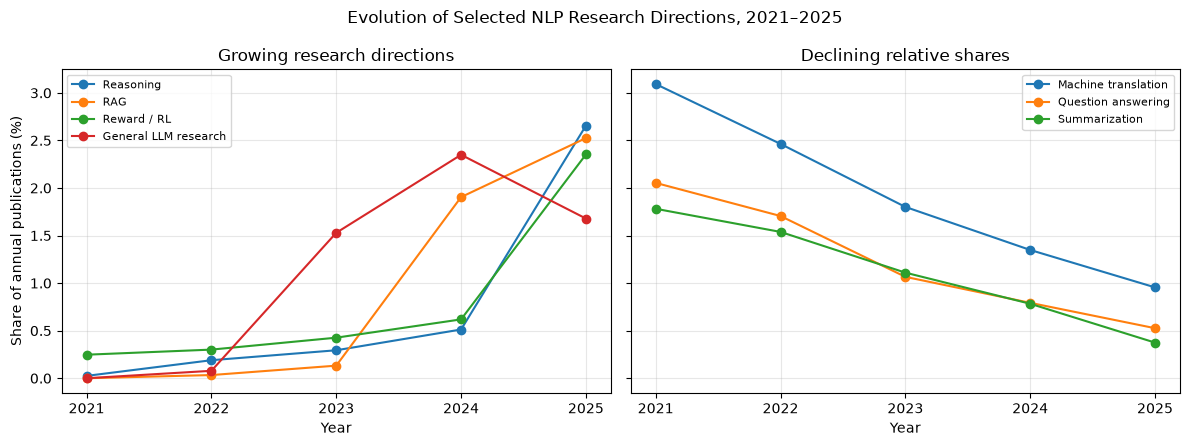

In [4]:
import matplotlib.pyplot as plt

growing = {
    149: "Reasoning",
    15: "RAG",
    19: "Reward / RL",
    76: "General LLM research"
}

declining = {
    34: "Machine translation",
    60: "Question answering",
    38: "Summarization"
}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)

for ax, topics, title in zip(
    axes,
    [growing, declining],
    ["Growing research directions", "Declining relative shares"]
):
    for cid, label in topics.items():
        ax.plot(
            shares.columns,
            shares.loc[cid],
            marker="o",
            label=label
        )

    ax.set_title(title)
    ax.set_xlabel("Year")
    ax.set_xticks(range(2021, 2026))
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

axes[0].set_ylabel("Share of annual publications (%)")

fig.suptitle("Evolution of Selected NLP Research Directions, 2021–2025")
plt.tight_layout()

plt.savefig(base / "nlp_topic_trends.png", dpi=200, bbox_inches="tight")
plt.show()
